# Next-day AQI category prediction with XGBoost

This notebook uses daily Beijing multi-station pollutant summaries with ERA5 weather (2013–2025) to calculate daily AQI labels and predict each station's next calendar-day category from today's six pollutant summaries.

## Standard and averaging periods

This notebook uses the exact AQI breakpoint table documented in [sets.ipynb](Data_Science/Notebooks/sets.ipynb), which follows China's **HJ 633-2026**. Daily AQI uses 24-hour means for PM2.5, PM10, SO2, NO2 and CO, plus the day's maximum trailing 8-hour O3 average. When that O3 average exceeds 800 µg/m³, the standard uses the daily maximum 1-hour O3 value instead. Concentrations are µg/m³ except CO (mg/m³); source CO readings are converted from µg/m³ to mg/m³. Daily 24-hour means require >=20 valid hours; valid O3 windows require >=6 hourly values, with >=14 windows ending 08:00–23:00. Concentrations are rounded to integer µg/m³ / 0.1 mg/m³; IAQI and AQI are rounded upward.

The AQI category names and breakpoint values follow the table in your provided image (also documented in sets.ipynb). The official standard reference is [MEE, HJ 633-2026](https://www.mee.gov.cn/ywgz/fgbz/bz/bzwb/jcffbz/202602/t20260225_1144441.shtml). The HJ 633-2026 Table 3 category ranges are Excellent (0–50), Good (51–100), Lightly polluted (101–150), Moderately polluted (151–200), Heavily polluted (201–300), Severely polluted (301–500).

AQI classes are ordinal but modeled as nominal classes. This is an educational model, not an official forecast or health advisory.

In [3]:
import os
import re
import sys
from pathlib import Path
import math

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

try:
    from sqlalchemy import create_engine, text
    import pymysql  # noqa: F401 - driver used by the default MySQL URL
except ImportError as error:
    raise ImportError(
        "Database loading requires SQLAlchemy and PyMySQL. In a notebook cell run "
        "%pip install sqlalchemy pymysql, then restart the kernel."
    ) from error

try:
    import sklearn
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
    from sklearn.preprocessing import LabelEncoder
    from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error, classification_report, confusion_matrix, ConfusionMatrixDisplay
except ImportError as error:
    raise ImportError(
        "Model training requires scikit-learn. In a notebook cell run "
        "%pip install scikit-learn, then restart the kernel."
    ) from error

try:
    import xgboost
    from xgboost import XGBClassifier
except ImportError as error:
    raise ImportError(
        "The six-class model requires XGBoost. In a notebook cell run "
        "%pip install xgboost, then restart the kernel."
    ) from error

try:
    import matplotlib.pyplot as plt
except ImportError as error:
    raise ImportError("Confusion-matrix plotting requires matplotlib; run %pip install matplotlib.") from error

# Locate the shared AQI helper whether Jupyter starts in this folder,
# the project root, or the parent Data_Science folder.
NOTEBOOK_DIR = Path.cwd().resolve()
search_roots = [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
helper_candidates = []
for root in search_roots:
    helper_candidates.extend([
        root / "app" / "aqi_labels.py",
        root / "air-quality-classification" / "app" / "aqi_labels.py",
        root / "Notebooks" / "aqi_labels.py",
        root / "Data_Science" / "Notebooks" / "aqi_labels.py",
    ])
helper_file = next((candidate for candidate in helper_candidates if candidate.is_file()), None)
if helper_file is None:
    raise FileNotFoundError(
        "Could not locate app/aqi_labels.py. Searched from the notebook's current "
        f"working directory and its parent folders: {NOTEBOOK_DIR}"
    )
helper_dir = helper_file.parent.resolve()
if str(helper_dir) not in sys.path:
    sys.path.insert(0, str(helper_dir))
from aqi_labels import AQI_CATEGORIES, O3_1H_BREAKPOINTS, POLLUTANT_BREAKPOINTS, category_codes, interpolate_iaqi

RANDOM_STATE=42
POLLUTANT_FEATURES=["PM2.5","PM10","SO2","NO2","CO","O3"]
FEATURES=POLLUTANT_FEATURES
AQI_STANDARD="HJ 633—2026 (effective 2026-03-01; breakpoints match sets.ipynb and the provided table)"
CATEGORY_THRESHOLDS=[50,100,150,200,300,float("inf")]
CATEGORY_LABELS=[AQI_CATEGORIES[i] for i in range(1,7)]
CATEGORY_ENGLISH=CATEGORY_LABELS.copy()
SOURCE_TABLE="aqi_daily"
EXPECTED_SOURCE_ROWS=51_920
DB_URL=os.environ.get("AIR_QUALITY_DB_URL","mysql+pymysql://root:@localhost/air_quality")


## 1. Load the daily pollutant-and-weather table from MySQL

This notebook reads `air_quality.aqi_daily`, created by `hourly_to_daily_pollutant_conversion.ipynb`. It does not load the model data from CSV. The six-class next-day model uses the daily pollutant fields; the ERA5 weather columns remain available in the loaded database table for future weather-feature models.


In [4]:
if not re.fullmatch(r"[A-Za-z0-9_]+",SOURCE_TABLE):
    raise ValueError(f"Invalid MySQL table name: {SOURCE_TABLE!r}")
engine=create_engine(DB_URL,pool_pre_ping=True)
try:
    with engine.connect() as connection:
        source_df=pd.read_sql_query(text(f"SELECT * FROM {SOURCE_TABLE}"),connection)
except Exception as error:
    raise RuntimeError(
        f"Could not load {SOURCE_TABLE!r} from the air_quality database. Check MySQL, "
        "AIR_QUALITY_DB_URL, the table name, SQLAlchemy, and PyMySQL. "
        f"Original database error: {error}"
    ) from error
print(f"Loaded source rows: {len(source_df):,}")
if len(source_df)!=EXPECTED_SOURCE_ROWS:
    print(f"Note: expected {EXPECTED_SOURCE_ROWS:,} rows, found {len(source_df):,}; continuing after schema validation.")
required_daily_columns=["date","station","station_id","PM2.5","PM10","SO2","NO2","CO","O3","O3_1h_max"]
missing_daily=[column for column in required_daily_columns if column not in source_df.columns]
if missing_daily:
    raise KeyError(f"air_quality.{SOURCE_TABLE} is missing required columns: {missing_daily}")
if source_df.duplicated(["station_id","date"]).any():
    raise ValueError(f"air_quality.{SOURCE_TABLE} contains duplicate station-days.")
display(source_df.head())
print("Columns:",source_df.columns.tolist())
print("Stations:",source_df.station.nunique(),"Date range:",pd.to_datetime(source_df["date"]).min().date(),"to",pd.to_datetime(source_df["date"]).max().date())


Loaded source rows: 51,920


,date,station,PM2.5,PM10,SO2,NO2,CO,O3,PM2.5_valid_hours,PM10_valid_hours,...,wd_cos,temperature_hours,pressure_hours,dewpoint_hours,humidity_hours,rain_hours,wind_speed_hours,wind_direction_hours,weather_matched,weather_station_matches_pollutant
0,2013-03-01,Aotizhongxin,7.125000,10.750000,11.708333,22.583333,0.429167,74.500,24,24,...,0.874674,24,24,24,24,24,24,24,1,1
1,2013-03-01,Changping,5.083333,18.958333,16.041667,15.333333,0.387500,88.875,24,24,...,0.867750,24,24,24,24,24,24,24,1,1
2,2013-03-01,Dingling,6.375000,6.270833,3.000000,2.333333,0.204167,86.000,24,24,...,0.867750,24,24,24,24,24,24,24,1,1
3,2013-03-01,Dongsi,6.416667,9.875000,8.291667,28.229167,0.389583,88.000,24,24,...,0.874674,24,24,24,24,24,24,24,1,1
4,2013-03-01,Guanyuan,7.541667,11.666667,8.500000,28.500000,0.400000,74.000,24,24,...,0.863489,24,24,24,24,24,24,24,1,1


Columns: ['date', 'station', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'PM2.5_valid_hours', 'PM10_valid_hours', 'SO2_valid_hours', 'NO2_valid_hours', 'CO_valid_hours', 'O3_1h_max', 'station_id', 'weather_station', 'TEMP_mean', 'TEMP_range', 'PRES_mean', 'DEWP_mean', 'RH_mean', 'RAIN_sum', 'WSPM_mean', 'wd_sin', 'wd_cos', 'temperature_hours', 'pressure_hours', 'dewpoint_hours', 'humidity_hours', 'rain_hours', 'wind_speed_hours', 'wind_direction_hours', 'weather_matched', 'weather_station_matches_pollutant']
Stations: 12 Date range: 2013-03-01 to 2025-01-04


## 2. Calculate daily AQI labels and next-day targets

The database already stores daily pollutant summaries. Calculate each pollutant sub-index from the project breakpoint tables, then use the highest available sub-index as daily AQI. CO values are treated as mg/m³, matching the source concentration units and CO breakpoints. Pair each station-day with the next calendar day’s category; rows without an exact next-day target are excluded.


In [5]:
# Work directly from the daily database table; no CSV or hourly aggregation is used here.
daily=source_df[["date","station","station_id",*POLLUTANT_FEATURES,"O3_1h_max"]].copy()
daily["date"]=pd.to_datetime(daily["date"],errors="coerce").dt.normalize()
for column in [*POLLUTANT_FEATURES,"O3_1h_max"]:
    daily[column]=pd.to_numeric(daily[column],errors="coerce")

# Compute pollutant IAQIs from the stored daily values. For high ozone, use the
# daily 1-hour maximum according to the shared helper's 800 ug/m3 rule.
iaqi_columns=[]
for pollutant in POLLUTANT_FEATURES:
    concentration=daily[pollutant]
    iaqi_column=f"{pollutant}_iaqi"
    if pollutant=="O3":
        ozone_8h_iaqi=interpolate_iaqi(concentration,POLLUTANT_BREAKPOINTS["O3"])
        ozone_1h_iaqi=interpolate_iaqi(daily["O3_1h_max"],O3_1H_BREAKPOINTS)
        ozone_8h_iaqi.loc[concentration.gt(800)]=ozone_1h_iaqi.loc[concentration.gt(800)]
        daily[iaqi_column]=ozone_8h_iaqi.round()
    else:
        daily[iaqi_column]=interpolate_iaqi(concentration,POLLUTANT_BREAKPOINTS[pollutant]).round()
    iaqi_columns.append(iaqi_column)

daily["AQI"]=daily[iaqi_columns].max(axis=1,skipna=True)
daily["category_code"]=category_codes(daily["AQI"])
daily["category"]=daily["category_code"].map(AQI_CATEGORIES)
daily["main_pollutant"]=daily[iaqi_columns].fillna(-1).idxmax(axis=1).str.removesuffix("_iaqi")
daily.loc[daily[iaqi_columns].isna().all(axis=1),"main_pollutant"]=np.nan

print(f"Daily station records from MySQL: {len(daily):,}")
print("Daily category counts:")
display(daily.category.value_counts(dropna=False))
display(daily[["date","station",*POLLUTANT_FEATURES,"AQI","category"]].head())

# Pair today's pollutant summaries with this station's next-calendar-day AQI category.
features_today=daily[["date","station",*FEATURES]].copy()
targets_next=daily[["date","station","category","AQI","main_pollutant"]].copy()
targets_next["date"]=targets_next["date"]-pd.Timedelta(days=1)
targets_next=targets_next.rename(columns={"category":"target_category","AQI":"target_AQI","main_pollutant":"target_main_pollutant"})
data=features_today.merge(targets_next,on=["date","station"],how="inner",validate="one_to_one")
data=data.dropna(subset=["target_category"]).copy()
print(f"Exact next-calendar-day training examples: {len(data):,}")


Daily station records from MySQL: 51,920
Daily category counts:


category
Good                   18239
Lightly polluted       13081
Excellent              11624
Moderately polluted     4358
Heavily polluted        2330
NaN                     1642
Severely polluted        646
Name: count, dtype: int64

,date,station,PM2.5,PM10,SO2,NO2,CO,O3,AQI,category
0,2013-03-01,Aotizhongxin,7.125000,10.750000,11.708333,22.583333,0.429167,74.500,37.0,Excellent
1,2013-03-01,Changping,5.083333,18.958333,16.041667,15.333333,0.387500,88.875,44.0,Excellent
2,2013-03-01,Dingling,6.375000,6.270833,3.000000,2.333333,0.204167,86.000,43.0,Excellent
3,2013-03-01,Dongsi,6.416667,9.875000,8.291667,28.229167,0.389583,88.000,44.0,Excellent
4,2013-03-01,Guanyuan,7.541667,11.666667,8.500000,28.500000,0.400000,74.000,37.0,Excellent


Exact next-calendar-day training examples: 50,266


## 3. Chronological split, tuning, and baseline

The latest 20% of unique dates are held out, keeping all stations on each date together. Expanding-window CV and median imputation are confined to the earlier training dates. The majority-class classifier is the baseline.

In [6]:
dates=np.array(sorted(data.date.unique())); cut=int(len(dates)*.8)
train_dates,test_dates=dates[:cut],dates[cut:]
train=data[data.date.isin(train_dates)].copy(); test=data[data.date.isin(test_dates)].copy()
X_train=train[FEATURES]; X_test=test[FEATURES]
y_train_labels=train.target_category.astype(str)
y_test=test.target_category.astype(str)
label_encoder=LabelEncoder()
y_train=label_encoder.fit_transform(y_train_labels)
y_test_codes=label_encoder.transform(y_test)
print(f"Train {len(train):,} through {train.date.max().date()}; test {len(test):,}, {test.date.min().date()}–{test.date.max().date()}")
train_date_codes=pd.factorize(train.date,sort=True)[0]; unique_train_dates=np.unique(train_date_codes); folds=[]
for train_date_idx,val_date_idx in TimeSeriesSplit(n_splits=4).split(unique_train_dates):
    folds.append((np.flatnonzero(np.isin(train_date_codes,train_date_idx)),np.flatnonzero(np.isin(train_date_codes,val_date_idx))))
params={"classifier__n_estimators":[120,240],"classifier__max_depth":[3,5],"classifier__learning_rate":[0.06]}
pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("classifier",XGBClassifier(objective="multi:softprob",num_class=len(label_encoder.classes_),eval_metric="mlogloss",random_state=RANDOM_STATE,n_jobs=4,tree_method="hist",verbosity=0))])
search=GridSearchCV(pipe,params,scoring="f1_macro",cv=folds,n_jobs=1,refit=True,verbose=1).fit(X_train,y_train)
model=search.best_estimator_
# Keep the existing auxiliary AQI and primary-pollutant estimators as Random Forests.
auxiliary_rf_params={"n_estimators":300,"min_samples_leaf":3}
aqi_regressor=Pipeline([("imputer",SimpleImputer(strategy="median")),("regressor",RandomForestRegressor(random_state=RANDOM_STATE,n_jobs=-1,**auxiliary_rf_params))])
aqi_regressor.fit(X_train,train.target_AQI.astype(float))
primary_pollutant_model=Pipeline([("imputer",SimpleImputer(strategy="median")),("classifier",RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1,class_weight="balanced_subsample",**auxiliary_rf_params))])
primary_pollutant_model.fit(X_train,train.target_main_pollutant)
print("Best XGBoost parameters:",search.best_params_,"CV macro F1:",round(search.best_score_,4))


Train 40,266 through 2022-08-31; test 10,000, 2022-09-01–2025-01-03
Fitting 4 folds for each of 4 candidates, totalling 16 fits
Best XGBoost parameters: {'classifier__learning_rate': 0.06, 'classifier__max_depth': 3, 'classifier__n_estimators': 120} CV macro F1: 0.3077


## 4. Held-out evaluation

accuracy                    0.5212
precision_macro             0.3283
recall_macro                0.2759
f1_macro                    0.2790
baseline_accuracy           0.3895
baseline_f1_macro           0.0934
aqi_mae                    27.3807
main_pollutant_accuracy     0.5949
dtype: float64

                     precision    recall  f1-score   support

          Excellent      0.661     0.532     0.590      3209
               Good      0.484     0.670     0.562      3895
   Heavily polluted      0.000     0.000     0.000       111
   Lightly polluted      0.447     0.392     0.418      2194
Moderately polluted      0.378     0.061     0.104       561
  Severely polluted      0.000     0.000     0.000        30

           accuracy                          0.521     10000
          macro avg      0.328     0.276     0.279     10000
       weighted avg      0.520     0.521     0.506     10000



,Predicted Excellent,Predicted Good,Predicted Heavily polluted,Predicted Lightly polluted,Predicted Moderately polluted,Predicted Severely polluted
Actual Excellent,1708,1347,0,154,0,0
Actual Good,729,2609,0,529,28,0
Actual Heavily polluted,7,38,0,60,6,0
Actual Lightly polluted,127,1176,8,861,22,0
Actual Moderately polluted,11,213,1,302,34,0
Actual Severely polluted,1,10,0,19,0,0


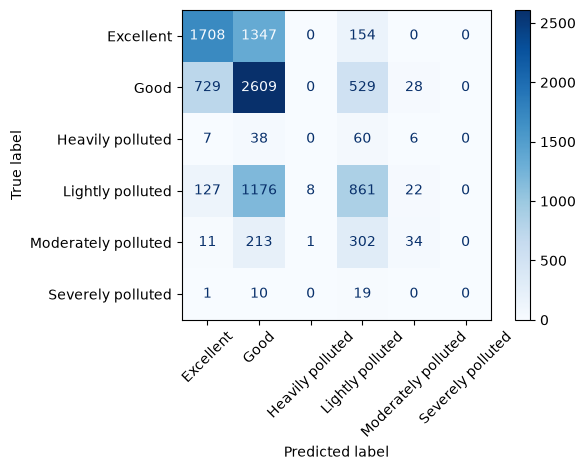

In [7]:
pred_codes=model.predict(X_test).astype(int); pred=label_encoder.inverse_transform(pred_codes); majority=y_train_labels.value_counts().idxmax(); baseline=np.repeat(majority,len(y_test))
metrics={"accuracy":accuracy_score(y_test,pred),"precision_macro":precision_score(y_test,pred,average="macro",zero_division=0),"recall_macro":recall_score(y_test,pred,average="macro",zero_division=0),"f1_macro":f1_score(y_test,pred,average="macro",zero_division=0),"baseline_accuracy":accuracy_score(y_test,baseline),"baseline_f1_macro":f1_score(y_test,baseline,average="macro",zero_division=0)}
metrics["aqi_mae"]=mean_absolute_error(test.target_AQI,aqi_regressor.predict(X_test))
metrics["main_pollutant_accuracy"]=accuracy_score(test.target_main_pollutant,primary_pollutant_model.predict(X_test))
display(pd.Series(metrics).round(4))
labels=label_encoder.classes_.tolist()
print(classification_report(y_test,pred,labels=labels,target_names=labels,zero_division=0,digits=3))
cm=confusion_matrix(y_test,pred,labels=labels)
display(pd.DataFrame(cm,index=["Actual "+x for x in labels],columns=["Predicted "+x for x in labels]))
ConfusionMatrixDisplay(cm,display_labels=labels).plot(cmap="Blues",xticks_rotation=45,values_format="d"); plt.tight_layout(); plt.show()

## 5. Reusable prediction function

Inputs come from **completed same-day pollutant summaries** in the database, not instantaneous readings: 24-hour means for PM2.5, PM10, SO2, NO2 and CO, and daily maximum rolling 8-hour O3 mean. Units are µg/m³ except CO, mg/m³ (convert hourly source CO from µg/m³ by multiplying by 0.001). O3 is the daily maximum trailing 8-hour mean with >=6 valid observations per window and >=14 valid windows ending 08:00–23:00. The backend must compute these same windows before calling the function.

In [8]:
def predict_next_day_aqi(pm25,pm10,so2,no2,co,o3):
    """Predict tomorrow from today's six completed pollutant summaries.
    Pollutants: 24-hour means except O3 (daily max trailing 8-hour mean);
    CO is mg/m³, other pollutants µg/m³.
    """
    row=pd.DataFrame([[pm25,pm10,so2,no2,co,o3]],columns=FEATURES)
    values=[pm25,pm10,so2,no2,co,o3]
    if not np.isfinite(np.asarray(values,dtype=float)).all():
        raise ValueError("All pollutant inputs must be finite numbers")
    if any(float(value)<0 for value in values):
        raise ValueError("Pollutant inputs must be non-negative")
    probs=model.predict_proba(row)[0]
    c=label_encoder.inverse_transform([int(model.classes_[int(np.argmax(probs))])])[0]
    predicted_aqi=int(np.clip(np.ceil(aqi_regressor.predict(row)[0]),0,500))
    main_pollutant=primary_pollutant_model.predict(row)[0]
    return {"predicted_category":c,"predicted_aqi":predicted_aqi,"predicted_main_pollutant":main_pollutant,"horizon":"next calendar day","standard":AQI_STANDARD}
predict_next_day_aqi(35,70,8,30,.7,110)

{'predicted_category': 'Good',
 'predicted_aqi': 103,
 'predicted_main_pollutant': 'PM2.5',
 'horizon': 'next calendar day',
 'standard': 'HJ 633—2026 (effective 2026-03-01; breakpoints match sets.ipynb and the provided table)'}

## 6. Save fitted model with requirements and evaluation


In [9]:
artifact={"model":model,"label_encoder":label_encoder,"classifier_name":"XGBoostClassifier","aqi_regressor":aqi_regressor,"primary_pollutant_model":primary_pollutant_model,"feature_requirements":{"features_in_order":FEATURES,"numeric_features":FEATURES,"units":{"PM2.5":"µg/m³","PM10":"µg/m³","SO2":"µg/m³","NO2":"µg/m³","CO":"mg/m³ (source µg/m³ converted by 0.001)","O3":"µg/m³"},"averaging_periods":{"PM2.5":"same-day 24-hour mean","PM10":"same-day 24-hour mean","SO2":"same-day 24-hour mean","NO2":"same-day 24-hour mean","CO":"same-day 24-hour mean","O3":"same-day maximum trailing 8-hour mean; at least six valid hours per window and 14 valid windows ending 08:00–23:00"}},"aqi_standard":AQI_STANDARD,"standard_source":"https://www.mee.gov.cn/ywgz/fgbz/bz/bzwb/jcffbz/202602/t20260225_1144441.shtml","category_mapping":{str(i):{"label":c} for i,c in enumerate(CATEGORY_LABELS,start=1)},"evaluation_metrics":{k:float(v) for k,v in metrics.items()},"training_period":[str(train.date.min().date()),str(train.date.max().date())],"test_period":[str(test.date.min().date()),str(test.date.max().date())],"best_parameters":search.best_params_,"sklearn_version":sklearn.__version__,"xgboost_version":xgboost.__version__}
model_path=Path.cwd()/"aqi_next_day_xgboost.joblib"
joblib.dump(artifact,model_path)
print("Saved:",model_path.resolve(),"size MB:",round(model_path.stat().st_size/1e6,2))
dataset_path=Path.cwd()/"aqi_model_dataset.csv"
data.to_csv(dataset_path,index=False)
print(f"Saved model dataset: {dataset_path.resolve()} ({len(data):,} rows)")

Saved: C:\Data_Science\Data_Science\air-quality-classification\notebooks\aqi_next_day_xgboost.joblib size MB: 653.26
Saved model dataset: C:\Data_Science\Data_Science\air-quality-classification\notebooks\aqi_model_dataset.csv (50,266 rows)


## 7. Findings, limitations, web integration

The six-class classifier is XGBoost. Use the held-out scores, class supports and confusion matrix above to assess performance against the majority baseline. Macro scores weight each class equally; accuracy can conceal poor rare-class recall.

**Limitations:** 2013–2017 Beijing observations may not generalize to current conditions, other cities, or sensors. There are no weather forecasts, seasonal/calendar features, or lagged AQI. Classes are imbalanced and ordinal, while this classifier treats them nominally. Labels are recomputed retrospectively under HJ 633—2026. The stated completeness filters are simplified; validate monitor quality and aggregation against HJ 633—2026, HJ 663, and monitoring QA requirements before operational or health use.

**Web integration:** Load the joblib artifact at backend startup, aggregate hourly inputs using the exact documented units/windows, validate completeness, then return predicted category and probabilities with date and standard metadata. Monitor input drift and retrain on recent data. Do not present predictions as official AQI reports.